In [67]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

%matplotlib widget

#tp = 2 * np.pi

In [68]:
# ---------- basic operators ----------
def destroy(N):
    return np.diag(np.sqrt(np.arange(1, N)), 1).astype(complex)

def dag(A):
    return A.conj().T

def ket(N, k):
    v = np.zeros(N, complex); v[k] = 1
    return v

def proj(v):
    return np.outer(v, v.conj())

def transmon(a, delta, alpha):
    """Duffing oscillator: delta*n + alpha/2 * a†a†aa"""
    return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a

def model(t, A, B, f, T, ph):
    return B + A * np.exp(-t/T) * np.cos(2 * np.pi * f * t + ph)




In [69]:
# ---------- Lindblad solver ----------
def liouvillian(H, c_ops):
    """Superoperator L such that d vec(rho)/dt = L vec(rho) (row-major vec)."""
    d = H.shape[0]; I = np.eye(d)

    # using the ODE d[vec(rho)]/dt = L@vec(rho)
    # for 2D vec(ρ) = (ρ00, ρ01, ρ10, ρ11)
    # the solution for the ODE is vec(ρ(t)) = expm(L*t) @ vec(ρ(0))
    # ρ is multiplied from both sides: Hρ − ρH, CρC†, and so on
    # it can’t be writen as one matrix times the matrix ρ
    # The conversion rule (for NumPy’s row-major ravel) is:
    # vec(A·ρ·B) = (A ⊗ Bᵀ) · vec(ρ), meaning:
    # −i[Hρ] = −iHρ + iρH = −iHρI + iIρH = −i(H ⊗ I − I ⊗ Hᵀ)*vec(ρ) = L*vec(ρ), then L=−i(H ⊗ I − I ⊗ Hᵀ)

    L = -1j * (np.kron(H, I) - np.kron(I, H.T)) #  vec(−i[Hρ]) = −i(H ⊗ I − I ⊗ Hᵀ)*vec(ρ)

    # for 1 quabit, c_ops includes relaxation and pure dephasing, C1 = sqrt(1/T1) * a, C2 = sqrt(2/Tphi) * n
    # for 2 qubits, c_ops includes relexation only, C1 = sqrt(1/T1) * a1, C2 = sqrt(1/T1) * a2
    #print('c_ops = [np.sqrt(1 / T1) * a,        # relaxation\n'
    #      '         np.sqrt(2 / Tphi) * n]      # pure dephasing')
    #print('c_ops =\n', c_ops[0].shape, '\n\n', c_ops[1].shape)
    #print('L =\n', L.shape)
    #assert()

    for C in c_ops:
        CdC = dag(C) @ C # C†C=1/T1 * a†a and 2/Tphi * n^2
        #print('C =\n', C, '\n\nCdC =\n', CdC)

        # for 1 qubit L = vec(−i[Hρ]) + vec(1/T1*aρa† − 1/2T1*(nρ + ρn)) + vec(2/Tphi*nρn − 1/Tphi*(n^2ρ + ρn^2)) 
        # for 2 qubits L = vec(−i[Hρ]) + vec(1/T1*aρa† − 1/2T1*(nρ + ρn)) for 2 qubits, C1 = sqrt(1/T1) * a1, C2 = sqrt(1/T1) * a2 

        L += np.kron(C, C.conj()) - 0.5 * np.kron(CdC, I) - 0.5 * np.kron(I, CdC.T)
        #print('dL =\n', np.kron(C, C.conj()) - 0.5 * np.kron(CdC, I) - 0.5 * np.kron(I, CdC.T))

    #assert()

    return L


# for 2 qubits
# mesolve(H_two(0), k2(1, 0), t2, c2, [proj(k2(1, 0)), proj(k2(0, 1))])


def mesolve(H, psi0, t, c_ops, e_ops):
    """Time-independent H, uniform time grid. Returns <E>(t) for each E in e_ops."""
    # starting with psi0
    d = H.shape[0]
    rho = proj(psi0).ravel()

    #print('H =\n', H.shape, '\n')
    #print('psi =\n', psi0.real,'\n')
    #print('rho =\n', rho.real)
    #print('c_ops =\n', c_ops.shape, '\n')
    #print('e_ops =\n', e_ops[0], '\n\n', e_ops[1], '\n\n', e_ops[2]) # for 1 qubit
    #print('e_ops =\n', e_ops[0], '\n\n', e_ops[1]) # for 2 qubits
    #assert()

    # one-step propagator, P=e(L*dt), Rho propogation: rho(t+dt) = P @ rho(t), P is const for each time step dt
    P = expm(liouvillian(H, c_ops) * (t[1] - t[0]))   

    Eout = np.empty((len(e_ops), len(t)))
    for i in range(len(t)):
        r = rho.reshape(d, d) # rho is updated every dt
        #print('r =\n', r)
        #print('e_ops[0] =\n', e_ops[0])

        # Eout[:,i] = <E>(t) = Tr(E @ rho(t)) for each E in e_ops, E is real-valued observable, rho is complex-valued density matrix
        # every E in e_ops is for different eigenvalue (energy level)
        # per each energy level, we have a different E, and we want to compute the expectation value of that E at time t

        Eout[:, i] = [np.real(np.trace(E @ r)) for E in e_ops] 
        #print('Eout =\n', Eout[:, i])
        
        rho = P @ rho # update rho(t+dt) = P @ rho(t) 
        #print('rho(t+dt) =\n', rho)
        #if i==3: break

    return Eout
# For time-dependent drives (shaped pulses), replace the fixed propagator with
# scipy.integrate.solve_ivp on f(t, rho) = L(t) @ rho.


def solve_Ramsey(P_half, P_wait, taus, psi_test, c_ops):

    proj1 = proj(ket(N, 1))                      # proj of psi = |1>
    rho = P_half @ proj(ket(N, 0)).ravel()       # start in |0>, apply first pi/2 to get |+> = (|0> + |1>)/sqrt(2)

    P1 = np.empty(len(taus))
    for i in range(len(taus)):
        r = (P_half @ rho).reshape(N, N)         # second pi/2 (on a copy) and each time with wait time tau[i] in between
        P1[i] = np.real(np.trace(proj1 @ r))     # measure P1 = Tr(|1><1| rho)
        rho = P_wait @ rho 

    return P1


In [95]:
# =========================================================
# 1. Single qubit: Rabi drive with T1, T2, and leakage to |2>
# =========================================================

from scipy.optimize import curve_fit


test_flag = 'Rabi' # 'Rabi', 'Ramsey', 'T1'

N = 3
a = destroy(N); n = dag(a) @ a
#print("a =\n", a)
#print("dag(a) =\n", dag(a))
#print("n =\n", n)

alpha = -2 * np.pi * 200      # anharmonicity -200 MHz
if test_flag == 'Rabi':
    Omega = 2 * np.pi * 10        # Rabi rate 10 MHz
    psi_test = ket(N, 0) # initial state |0>
    delta = 0              # drive detuning
elif test_flag == 'T1':
    Omega = 0
    psi_test = ket(N, 1) # initial state |1>
    delta = 0              # drive detuning
elif test_flag == 'Ramsey':
    Omega = 2 * np.pi * 10        # Rabi rate 10 MHz
    psi_test = (ket(N, 0) + ket(N, 1)) / np.sqrt(2) # initial state (|0> + |1>)/√2
    delta = 2 * np.pi * 1 # drive detuning for Ramsey experiment

T1, T2 = 50, 30        # relaxation and decoherence times in microseconds
Tphi = 1 / (1 / T2 - 1 / (2 * T1)) # dephasing time

c_ops = [np.sqrt(1 / T1) * a,        # relaxation
         np.sqrt(2 / Tphi) * n]      # pure dephasing

Tmax = int(T1 * 2)
t1 = np.linspace(0, Tmax, 2001*Tmax) # time grid in microseconds

H_free  = transmon(a, delta, alpha)             # basic transmon or during the wait (drive off)
H_pulse = H_free + Omega/2 * (a + dag(a))  
#print("\nH_pulse =\n", H_pulse)

if not (test_flag == 'Ramsey'):

    P = [proj(ket(N, k)) for k in range(N)]
    #print("\nP =\n", P[0], "\n\n", P[1], "\n\n", P[2])
    #print('\nket(N, k) =\n', ket(N, 0), '\n\n', ket(N, 1), '\n\n', ket(N, 2))
    #print('\nproj(ket(N, k)) =\n', proj(ket(N, 0)), '\n\n', proj(ket(N, 1)), '\n\n', proj(ket(N, 2)))
    Eout = mesolve(H_pulse, psi_test, t1, c_ops, P)

else: # only for Ramsey test

    t_half = (np.pi/2) / Omega                                # pi/2 pulse length
    P_half = expm(liouvillian(H_pulse, c_ops) * t_half)       # one pi/2 pulse, P_half = exp(L*t_half)

    dtau   = 0.02                                             # 20 ns wait step
    taus   = np.arange(0, 30, dtau)                           # wait times, us
    P_wait = expm(liouvillian(H_free, c_ops) * dtau)          # one wait step, P_wait = exp(L*dtau)

    P1 = solve_Ramsey(P_half, P_wait, taus, psi_test, c_ops)

    popt, _ = curve_fit(model, taus, P1, p0=[0.5, 0.5, 1.0, 20, 0]) # estimate model, initial guess: A=0.5, B=0.5, f=1 MHz, T=20 us, ph=0
    A, B, f, T2fit, ph = popt

    print(f"fringe frequency : {f:.4f} MHz   (set detuning {delta/(2*np.pi):.1f} MHz)")
    print(f"T2 (Ramsey)      : {T2fit:.2f} us  (set T2 = {T2} us)")
    print(f"amplitude, offset: {A:.3f}, {B:.3f}")


Max P1 = 0.9975, max leakage P2 = 1.42e-03


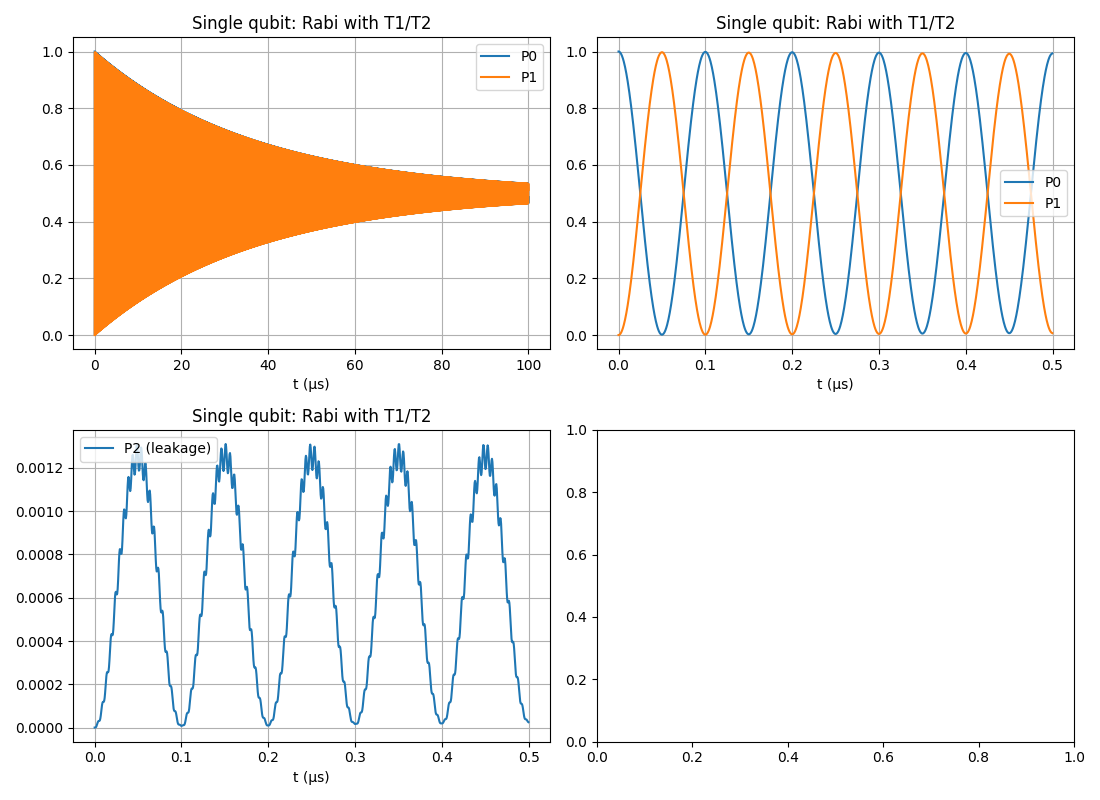

In [96]:
# ---------- plots ----------
if not (test_flag == 'Ramsey'):
    fig, ax1 = plt.subplots(2, 2, figsize=(11, 8))

    ax1[0, 0].plot(t1, Eout[0], label="P0"); 
    ax1[0, 0].plot(t1, Eout[1], label="P1");
    if test_flag == 'Rabi':
        ax1[0, 0].set(xlabel="t (µs)", title="Single qubit: Rabi with T1/T2"); 
    elif test_flag == 'T1':
        ax1[0, 0].set(xlabel="t (µs)", title="Single qubit: T1 decay");

    ax1[0, 0].legend(); ax1[0, 0].grid(True)

    # short t1
    short_t1 = t1[t1 <= 0.5]
    short_r1 = Eout[:, t1 <= 0.5]
    ax1[0, 1].plot(short_t1, short_r1[0], label="P0"); 
    ax1[0, 1].plot(short_t1, short_r1[1], label="P1"); 
    ax1[0, 1].set(xlabel="t (µs)", title="Single qubit: Rabi with T1/T2"); 
    ax1[0, 1].legend(); ax1[0, 1].grid(True)

    ax1[1, 0].plot(short_t1, short_r1[2], label="P2 (leakage)")
    ax1[1, 0].set(xlabel="t (µs)", title="Single qubit: Rabi with T1/T2"); 
    ax1[1, 0].legend(); ax1[1, 0].grid(True)

    #ax1[1, 0].set(xlabel="t (µs)", title="Single qubit: Rabi with T1/T2"); 
    #ax1[1, 0].legend()
    print(f"Max P1 = {Eout[1].max():.4f}, max leakage P2 = {Eout[2].max():.2e}")
else:
    fig, ax1 = plt.subplots(1, 1, figsize=(6, 4))
    ax1.plot(taus, P1, label="sim P1"); 
    #ax1.plot(taus, model(taus, A, B, f, T2fit, ph), '*', label="fit P1");
    env = B + abs(A) * np.exp(-taus / T2fit)
    ax1.plot(taus, env, label=f"envelope, T2 = {T2fit:.1f} µs")

    ax1.set(xlabel="tau (µs)", title="Single qubit: Ramsey with T1/T2"); 
    ax1.legend(); ax1.grid(True)
    
plt.tight_layout(); plt.show()


In [88]:
# =========================================================
# 2. Two transmons with exchange coupling g
# =========================================================
I = np.eye(N)
a1 = np.kron(a, I)                                  
# acts on transmon 1, identity on 2 
# np.kron(a, I) = [[0*I,I,0*I],[0*I,0*I,sqrt(2)*I],[0*I,0*I,0*I]]
# each number in the matrix is multiplied by the identity matrix I, so it acts on transmon 1 and leaves transmon 2 unchanged
# Here the √2 block is what lowers |2j⟩ → |1j⟩ with amplitude √2.

a2 = np.kron(I, a)                                  
# identity on 1, acts on transmon 2
# Here the √2 block is what lowers |i2⟩ → |i1⟩ with amplitude √2.

k2 = lambda i, j: np.kron(ket(N, i), ket(N, j))     # |ij⟩, index = i·N + j,
# if ket(3, 0) = [1, 0, 0], ket(3, 1) = [0, 1, 0], ket(3, 2) = [0, 0, 1]
# np.kron(ket(3, 1), ket(3, 0)) = [0, 0, 0, 1, 0, 0, 0, 0, 0] = |10⟩
# np.kron(ket(3, 1), ket(3, 2)) = [0, 0, 0, 0, 0, 1, 0, 0, 0] = |12⟩

g = 2 * np.pi * 5
alpha1 = alpha2 = -2 * np.pi * 200

# delta1=0 meaning transmon 1 is on resonance, delta2 is the diff between qubits
def H_two(delta2, delta1=0): 
    return (transmon(a1, delta1, alpha1) + transmon(a2, delta2, alpha2)
            + g * (dag(a1) @ a2 + a1 @ dag(a2)))

n1, n2 = dag(a1) @ a1, dag(a2) @ a2
#c2 = [np.sqrt(1 / T1) * a1, np.sqrt(1 / T1) * a2]  # relaxation of each qubit, no dephasing for speed
c2 = [np.sqrt(1/T1) * a1, np.sqrt(1/T1) * a2,       # relaxation of each qubit
      np.sqrt(2/Tphi) * n1, np.sqrt(2/Tphi) * n2]   # dephasing of each qubit

t2 = np.linspace(0, 0.3, 601)
#t2 = np.linspace(0, 5, 6001) # to see the impact of dephasing, but it takes longer to run

# (a) resonant swap |10> <-> |01>; iSWAP at t = pi/(2g) = 50 ns
r2 = mesolve(H_two(0), k2(1, 0), t2, c2, [proj(k2(1, 0)), proj(k2(0, 1))])

# (b) chevron: sweep qubit-2 detuning
detunings = np.linspace(-30, 30, 61)
chevron = np.array([mesolve(H_two(2 * np.pi * d), k2(1, 0), t2, [], [proj(k2(0, 1))])[0]
                    for d in detunings])

/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/3030096939.py:28: RuntimeWarning: divide by zero encountered in matmul
  n1, n2 = dag(a1) @ a1, dag(a2) @ a2
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/3030096939.py:28: RuntimeWarning: overflow encountered in matmul
  n1, n2 = dag(a1) @ a1, dag(a2) @ a2
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/3030096939.py:28: RuntimeWarning: invalid value encountered in matmul
  n1, n2 = dag(a1) @ a1, dag(a2) @ a2
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: RuntimeWarning: divide by zero encountered in matmul
  return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: RuntimeWarning: overflow encountered in matmul
  return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: Runt

/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: RuntimeWarning: divide by zero encountered in matmul
  return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: RuntimeWarning: overflow encountered in matmul
  return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/2385927413.py:17: RuntimeWarning: invalid value encountered in matmul
  return delta * dag(a) @ a + alpha / 2 * dag(a) @ dag(a) @ a @ a
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/3030096939.py:26: RuntimeWarning: divide by zero encountered in matmul
  + g * (dag(a1) @ a2 + a1 @ dag(a2)))
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykernel_88517/3030096939.py:26: RuntimeWarning: overflow encountered in matmul
  + g * (dag(a1) @ a2 + a1 @ dag(a2)))
/var/folders/ty/c88q5l55703cf6zwm5rr5_q00000gn/T/ipykerne

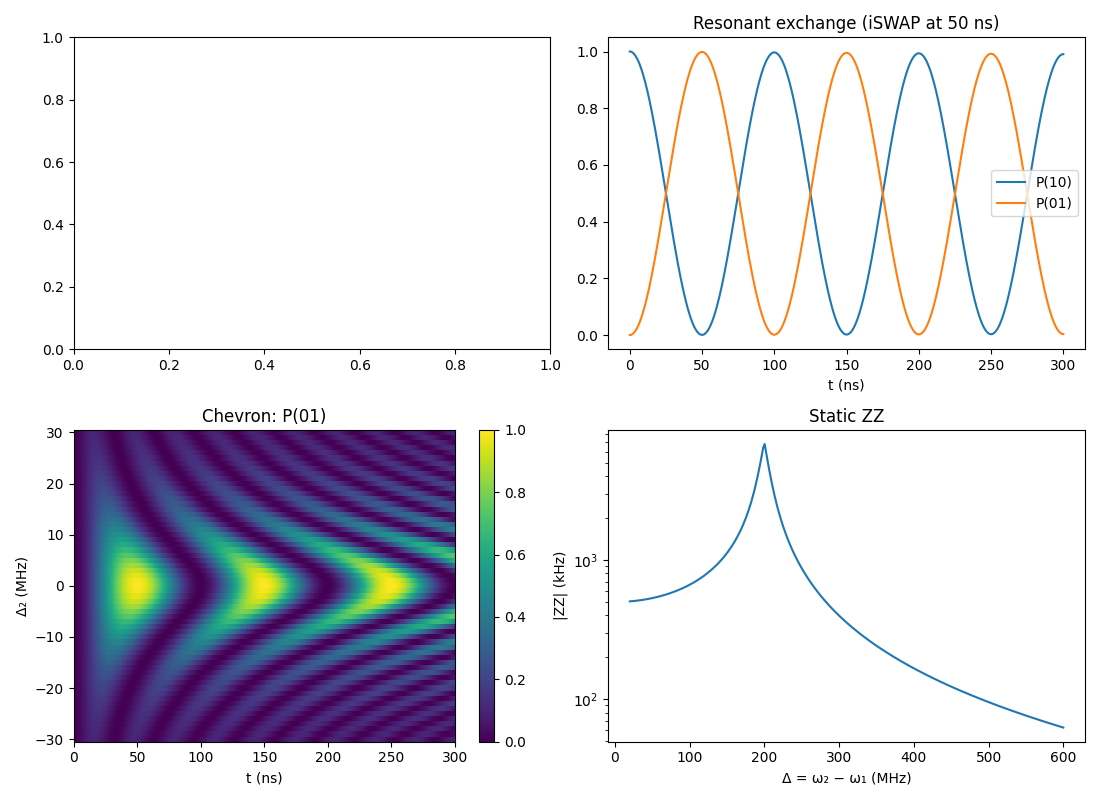

Max P1 = 0.5000, max leakage P2 = 0.00e+00
P(01) at 50 ns = 0.9984
ZZ at Δ = 100 MHz: 663 kHz


In [97]:
# (c) static ZZ vs detuning from eigenenergies
def zz(d2):
    E, V = np.linalg.eigh(H_two(d2))
    lev = lambda i, j: E[np.argmax(np.abs(V.conj().T @ k2(i, j)) ** 2)]
    return lev(1, 1) - lev(1, 0) - lev(0, 1) + lev(0, 0)

zz_det = np.linspace(20, 600, 300)
zz_vals = np.array([zz(2 * np.pi * d) for d in zz_det]) / (2 * np.pi) * 1e3   # kHz

# ---------- plots ----------
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
#ax[0, 0].plot(t1, r1[1], label="P1"); ax[0, 0].plot(t1, r1[2], label="P2 (leakage)")
#ax[0, 0].set(xlabel="t (µs)", title="Single qubit: Rabi with T1/T2"); ax[0, 0].legend()


ax[0, 1].plot(t2 * 1e3, r2[0], label="P(10)"); ax[0, 1].plot(t2 * 1e3, r2[1], label="P(01)")
ax[0, 1].set(xlabel="t (ns)", title="Resonant exchange (iSWAP at 50 ns)"); ax[0, 1].legend()

im = ax[1, 0].pcolormesh(t2 * 1e3, detunings, chevron, shading="auto")
ax[1, 0].set(xlabel="t (ns)", ylabel="Δ₂ (MHz)", title="Chevron: P(01)")
fig.colorbar(im, ax=ax[1, 0])

ax[1, 1].semilogy(zz_det, np.abs(zz_vals))
ax[1, 1].set(xlabel="Δ = ω₂ − ω₁ (MHz)", ylabel="|ZZ| (kHz)", title="Static ZZ")
plt.tight_layout(); plt.show()

print(f"Max P1 = {r1[1].max():.4f}, max leakage P2 = {r1[2].max():.2e}")
print(f"P(01) at 50 ns = {r2[1][np.argmin(abs(t2 - 0.05))]:.4f}")
print(f"ZZ at Δ = 100 MHz: {zz(2 * np.pi * 100) / (2 * np.pi) * 1e3:.0f} kHz")

In [112]:
# analysys using ri
"""What we can learn from the single-qubit simulation r1, and how to print/plot it."""
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#exec(open('qubit_sim.py').read().split('# =========================================================\n# 2.')[0]
#     .replace('plt.show()', ''))   # runs part 1: defines t1, r1, Omega, T1, T2 ...

P0, P1, P2 = r1            # r1 rows = populations of |0>,|1>,|2> vs time t1 (µs)

# ---------- 1. print a table ----------
print(f"{'t (ns)':>8} {'P0':>8} {'P1':>8} {'P2':>10}")
for i in range(0, 201, 10):                       # first 100 ns, every 5 ns
    print(f"{t1[i]*1e3:8.1f} {P0[i]:8.4f} {P1[i]:8.4f} {P2[i]:10.2e}")

# ---------- 2. numbers we can extract ----------
i_pi  = np.argmax(P1[:400])                       # first maximum of P1 = pi pulse
t_pi  = t1[i_pi]
Om_fit = np.pi / t_pi / (2*np.pi)                 # MHz
print(f"\npi-pulse time      : {t_pi*1e3:.1f} ns   (ideal {1e3/(2*Omega/(2*np.pi)):.1f} ns)")
print(f"Rabi frequency     : {Om_fit:.3f} MHz  (set {Omega/(2*np.pi):.1f} MHz)")
print(f"P1 at pi pulse     : {P1[i_pi]:.5f}  -> pi-pulse error {1-P1[i_pi]:.1e}")
print(f"max leakage P2     : {P2.max():.2e}")
print(f"trace check        : {np.abs(P0+P1+P2-1).max():.1e}")

# Fit damped Rabi: P1 = A/2 (1 - exp(-t/tau) cos(2 pi f t))
model = lambda t, A, f, tau: A/2*(1 - np.exp(-t/tau)*np.cos(2*np.pi*f*t))
(A, f, tau), _ = curve_fit(model, t1, P1, p0=[1, Om_fit, 20])
print(f"fit: f = {f:.4f} MHz, decay tau = {tau:.1f} us "
      f"(theory 2/(1/T1+1/T2) = {2/(1/T1+1/T2):.1f} us)")

# ---------- 3. plot ----------
blue, ink, muted = "#2a78d6", "#0b0b0b", "#52514e"
fig, ax = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                       gridspec_kw=dict(height_ratios=[2, 1]))
ax[0].plot(t1*1e3, P1, color=blue, lw=2)
ax[0].axvline(t_pi*1e3, color=muted, lw=1, ls="--")
ax[0].annotate(f"π pulse, {t_pi*1e3:.0f} ns", (t_pi*1e3, 1.0), xytext=(6, -14),
               textcoords="offset points", color=ink, fontsize=9)
ax[0].set(ylabel="P1 (excited population)", ylim=(-0.03, 1.08),
          title="Rabi oscillation, Ω/2π = 10 MHz, T1 = 50 µs, T2 = 30 µs")
ax[1].plot(t1*1e3, P2*1e3, color=blue, lw=2)
ax[1].set(ylabel="P2 (×10⁻³)", xlabel="time (ns)", title="Leakage to |2⟩")
for a in ax:
    a.grid(color="#e6e5e1", lw=0.8); a.spines[["top", "right"]].set_visible(False)
    a.set_xlim(0, 300); a.title.set_fontsize(10); a.title.set_ha("left"); a.title.set_x(0)
plt.tight_layout(); plt.savefig("qubit_rabi.png", dpi=150)


  t (ns)       P0       P1         P2
     0.0   1.0000   0.0000   0.00e+00
    15.0   0.7942   0.2055   2.56e-04
    30.0   0.3465   0.6527   8.13e-04
    45.0   0.0259   0.9729   1.21e-03
    60.0   0.0962   0.9026   1.12e-03
    75.0   0.4994   0.5000   6.22e-04
    90.0   0.9029   0.0969   1.23e-04
   105.0   0.9746   0.0254   4.00e-05
   120.0   0.6555   0.3440   4.46e-04
   135.0   0.2089   0.7901   1.01e-03
   150.0   0.0026   0.9961   1.27e-03
   165.0   0.2064   0.7926   1.02e-03
   180.0   0.6521   0.3474   4.55e-04
   195.0   0.9724   0.0275   4.47e-05
   210.0   0.9036   0.0963   1.17e-04
   225.0   0.5027   0.4967   6.05e-04
   240.0   0.1001   0.8988   1.10e-03
   255.0   0.0275   0.9713   1.19e-03
   270.0   0.3443   0.6549   7.99e-04
   285.0   0.7894   0.2104   2.57e-04
   300.0   0.9960   0.0040   1.63e-05

pi-pulse time      : 49.5 ns   (ideal 50.0 ns)
Rabi frequency     : 10.101 MHz  (set 10.0 MHz)
P1 at pi pulse     : 0.99717  -> pi-pulse error 2.8e-03
max leakage 